# Сравнение сетей Петри четырёх групп компьютеров

Цель - проверить, насколько сети одной группы описывают журналы других. Только **Microsoft-Windows-Kernel-Power** (как в ноутбуке 04), `Kernel-Power:41` применяется для разметки отказов, но не входит в трассы.

Группы: прежние компьютеры и три группы школьных машин.

## 1. Данные и параметры

Порог фильтрации совпадает с прежними экспериментами: не менее 20 сессий и 50 событий компоненты на машину. По умолчанию precision отключён: он значительно медленнее fitness.

In [9]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.cluster_comparison import prepare_component_logs, split_by_machine
from src.model_quality import _to_event_log
from src.models import transition_table

GROUPS = ["previous", "itplgn", "s-1547-3-410", "s-1547-3-413"]
MIN_SESSIONS = 20
MIN_EVENTS = 50
TEST_SHARE = 0.25
SEED = 42
MAX_TEST_SESSIONS = 100   # None = все тестовые сессии
COMPUTE_PRECISION = True
MAX_PRECISION_SESSIONS = 40  # None = все выбранные тестовые сессии

log, sessions = prepare_component_logs()
stats, splits = split_by_machine(log, MIN_SESSIONS, MIN_EVENTS, TEST_SHARE, SEED)
if set(splits) != set(GROUPS):
    raise ValueError(f"Ожидались группы {GROUPS}, обнаружены {list(splits)}")
display(stats.groupby("group").agg(
    machines=("machine_id", "count"),
    eligible=("eligible", "sum"),
    sessions=("sessions", "sum"),
    events=("events", "sum")
).reindex(GROUPS))
display(pd.DataFrame({g: {
    "train_machines": len(splits[g]["train"]),
    "test_machines": len(splits[g]["test"])
} for g in GROUPS}).T)
print("В построении моделей участвуют только train-машины.")
pm4py.util.constants.SHOW_PROGRESS_BAR = False

Школьные машины: 67, с нужными событиями: 67


,machines,eligible,sessions,events
group,,,,
previous,14,12,949,31496
itplgn,37,24,1528,25518
s-1547-3-410,15,14,2003,12803
s-1547-3-413,15,15,1533,7873


,train_machines,test_machines
previous,9,3
itplgn,18,6
s-1547-3-410,10,4
s-1547-3-413,11,4


В построении моделей участвуют только train-машины.


## 2. Обучающие и тестовые журналы

Для каждой группы строим сеть по части машин и проверяем её на оставшихся. Таким образом можно сравнить и свои, и чужие группы без оценки на обучающих данных.

In [10]:
train_ids = {m for g in GROUPS for m in splits[g]["train"]}
test_ids = {m for g in GROUPS for m in splits[g]["test"]}
assert train_ids.isdisjoint(test_ids)

train = log[log["machine_id"].isin(train_ids)].copy()
test = log[log["machine_id"].isin(test_ids)].copy()

def sample_sessions(data, limit, seed):
    if limit is None or data["case_id"].nunique() <= limit:
        return data
    rng = np.random.default_rng(seed)
    pools = {m: list(rng.permutation(sorted(part["case_id"].unique())))
             for m, part in data.groupby("machine_id", sort=True)}
    selected = []
    while len(selected) < limit and any(pools.values()):
        for machine in sorted(pools):
            if pools[machine] and len(selected) < limit:
                selected.append(pools[machine].pop())
    return data[data["case_id"].isin(selected)]

test_logs = {g: sample_sessions(test[test["group"] == g], MAX_TEST_SESSIONS, SEED)
             for g in GROUPS}
display(pd.DataFrame({g: {
    "train_sessions": train.loc[train["group"] == g, "case_id"].nunique(),
    "test_sessions_total": test.loc[test["group"] == g, "case_id"].nunique(),
    "test_sessions_used": test_logs[g]["case_id"].nunique(),
    "test_FAIL": int((test_logs[g]["activity"] == "END_FAIL").sum())
} for g in GROUPS}).T)

,train_sessions,test_sessions_total,test_sessions_used,test_FAIL
previous,772,156,100,58
itplgn,1007,353,100,80
s-1547-3-410,1461,526,100,68
s-1547-3-413,1009,524,100,34


## 3. Построение сетей Петри

Используется прежний алгоритм `pm4py.discover_petri_net_inductive`. Четыре групповые сети и одна общая обьединенная сеть (объединённые обучающие трассы). 

In [11]:
model_logs = {g: _to_event_log(train[train["group"] == g]) for g in GROUPS}
model_logs["all_groups"] = _to_event_log(train)
models = {}
rows = []
for name, pm_log in model_logs.items():
    start = time.perf_counter()
    net, im, fm = pm4py.discover_petri_net_inductive(pm_log)
    models[name] = (net, im, fm)
    rows.append({"model": name, "places": len(net.places),
                 "transitions": len(net.transitions), "arcs": len(net.arcs),
                 "build_seconds": round(time.perf_counter() - start, 2)})
display(pd.DataFrame(rows).set_index("model"))

,places,transitions,arcs,build_seconds
model,,,,
previous,44,62,136,1.20
itplgn,12,22,44,0.35
s-1547-3-410,9,14,28,0.07
s-1547-3-413,12,19,38,0.03
all_groups,18,34,70,2.32


## 4. Fitness и precision на своих и чужих группах

Строки - train, столбцы - test. Precision запускается отдельно при `COMPUTE_PRECISION=True`. Значения на диагонали тоже получены на , не обучающих машинах.

In [ ]:
fitness_logs = {g: _to_event_log(test_logs[g]) for g in GROUPS}
precision_logs = ({g: _to_event_log(sample_sessions(test_logs[g],
                   MAX_PRECISION_SESSIONS, SEED + 1)) for g in GROUPS}
                  if COMPUTE_PRECISION else {})
fitness = pd.DataFrame(index=list(models), columns=GROUPS, dtype=float)
precision = pd.DataFrame(index=list(models), columns=GROUPS, dtype=float)
for model_name, (net, im, fm) in models.items():
    for group in GROUPS:
        start = time.perf_counter()
        try:
            result = pm4py.fitness_token_based_replay(
                fitness_logs[group], net, im, fm)
            fitness.loc[model_name, group] = float(result["log_fitness"])
        except Exception as exc:
            print("Ошибка fitness:", model_name, group, repr(exc))
        print(f"{model_name} → {group}: fitness {fitness.loc[model_name, group]:.3f}, "
              f"{time.perf_counter()-start:.1f} с")
print("Fitness на тестовых машинах:")
display(fitness.round(3))

previous → previous: fitness 0.994; 0.8 с
previous → itplgn: fitness 0.976; 0.1 с
previous → s-1547-3-410: fitness 0.996; 0.0 с
previous → s-1547-3-413: fitness 0.992; 0.0 с
itplgn → previous: fitness 0.957; 2.4 с
itplgn → itplgn: fitness 1.000; 0.0 с
itplgn → s-1547-3-410: fitness 0.993; 0.0 с
itplgn → s-1547-3-413: fitness 0.996; 0.0 с
s-1547-3-410 → previous: fitness 0.933; 2.4 с
s-1547-3-410 → itplgn: fitness 0.999; 0.0 с
s-1547-3-410 → s-1547-3-410: fitness 1.000; 0.0 с
s-1547-3-410 → s-1547-3-413: fitness 1.000; 0.0 с
s-1547-3-413 → previous: fitness 0.994; 2.4 с
s-1547-3-413 → itplgn: fitness 1.000; 0.0 с
s-1547-3-413 → s-1547-3-410: fitness 1.000; 0.0 с
s-1547-3-413 → s-1547-3-413: fitness 1.000; 0.0 с
all_groups → previous: fitness 1.000; 0.6 с
all_groups → itplgn: fitness 1.000; 0.1 с
all_groups → s-1547-3-410: fitness 1.000; 0.0 с
all_groups → s-1547-3-413: fitness 1.000; 0.0 с
Fitness на тестовых машинах:


,previous,itplgn,s-1547-3-410,s-1547-3-413
previous,0.994,0.976,0.996,0.992
itplgn,0.957,1.000,0.993,0.996
s-1547-3-410,0.933,0.999,1.000,1.000
s-1547-3-413,0.994,1.000,1.000,1.000
all_groups,1.000,1.000,1.000,1.000


## 5. Precision
Обычно расчет долгий, выполняется при выборе `COMPUTE_PRECISION=True` в первой ячейке.

In [13]:
if COMPUTE_PRECISION:
    for model_name, (net, im, fm) in models.items():
        for group in GROUPS:
            start = time.perf_counter()
            try:
                precision.loc[model_name, group] = float(
                    pm4py.precision_token_based_replay(
                        precision_logs[group], net, im, fm))
            except Exception as exc:
                print("Ошибка precision:", model_name, group, repr(exc))
            print(f"{model_name} → {group}: precision "
                  f"{precision.loc[model_name, group]:.3f}; "
                  f"{time.perf_counter()-start:.1f} с")
    display(precision.round(3))
else:
    print("Precision отключён для быстрого запуска.")

previous → previous: precision 0.180; 8.1 с
previous → itplgn: precision 0.137; 0.5 с
previous → s-1547-3-410: precision 0.195; 0.4 с
previous → s-1547-3-413: precision 0.207; 0.1 с
itplgn → previous: precision 0.105; 8.5 с
itplgn → itplgn: precision 0.239; 0.3 с
itplgn → s-1547-3-410: precision 0.248; 0.1 с
itplgn → s-1547-3-413: precision 0.342; 0.0 с
s-1547-3-410 → previous: precision 0.168; 16.1 с
s-1547-3-410 → itplgn: precision 0.384; 0.2 с
s-1547-3-410 → s-1547-3-410: precision 0.446; 0.1 с
s-1547-3-410 → s-1547-3-413: precision 0.568; 0.0 с
s-1547-3-413 → previous: precision 0.122; 17.2 с
s-1547-3-413 → itplgn: precision 0.323; 0.2 с
s-1547-3-413 → s-1547-3-410: precision 0.359; 0.1 с
s-1547-3-413 → s-1547-3-413: precision 0.490; 0.0 с
all_groups → previous: precision 0.095; 40.0 с
all_groups → itplgn: precision 0.137; 0.4 с
all_groups → s-1547-3-410: precision 0.125; 0.2 с
all_groups → s-1547-3-413: precision 0.183; 0.1 с


,previous,itplgn,s-1547-3-410,s-1547-3-413
previous,0.180,0.137,0.195,0.207
itplgn,0.105,0.239,0.248,0.342
s-1547-3-410,0.168,0.384,0.446,0.568
s-1547-3-413,0.122,0.323,0.359,0.490
all_groups,0.095,0.137,0.125,0.183


## 6. Сравнение вероятностей наблюдаемых переходов

Используем функцию `transition_table`. Сравниваем по каждой группе наиболее частые переходы и их вероятности.

In [14]:
tables = {g: transition_table(train[train["group"] == g]) for g in GROUPS}
counts = pd.concat([
    t.assign(group=g)[["group", "src", "dst", "count", "prob"]]
    for g, t in tables.items()
], ignore_index=True)
top = (counts.groupby(["src", "dst"])["count"].sum()
       .nlargest(15).index)
comparison = counts.pivot_table(
    index=["src", "dst"], columns="group", values="prob"
).reindex(top).reindex(columns=GROUPS).fillna(0)
print("Вероятности 15 наиболее частых переходов (по обучающим данным):")
display(comparison.round(3))

Вероятности 15 наиболее частых переходов (по обучающим данным):


,group,previous,itplgn,s-1547-3-410,s-1547-3-413
src,dst,,,,
42,107,1.000,0.998,1.000,0.999
187,42,1.000,0.999,0.999,1.000
START,172,0.969,1.000,1.000,1.000
566,506,0.427,0.000,0.000,0.000
507,566,1.000,0.000,0.000,0.000
107,187,0.451,0.495,0.228,0.358
506,566,0.828,0.000,0.000,0.000
107,131,0.044,0.237,0.525,0.225
131,130,0.000,1.000,1.000,1.000


## 7. Матрицы качества и вывод

Высокий fitness означает, что сеть воспроизводит наблюдаемые трассы. Низкий precision означает, что сеть допускает слишком много лишних последовательностей.

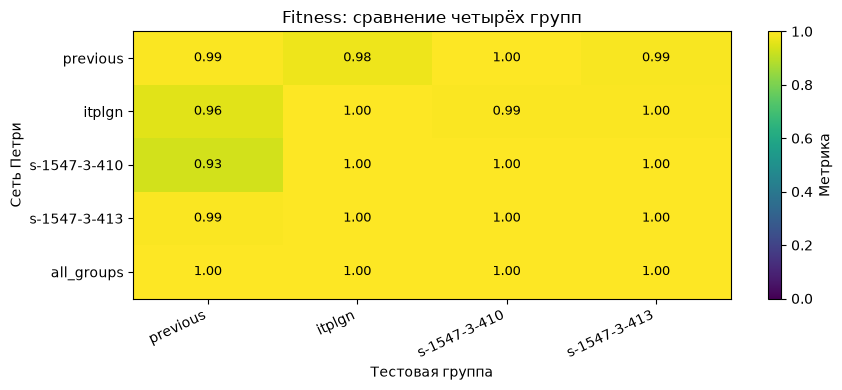

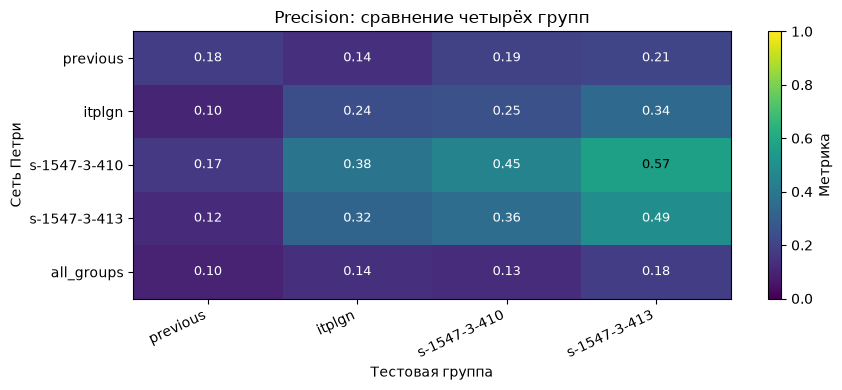

,mean_fitness
all_groups,1.000
s-1547-3-413,0.998
previous,0.990
itplgn,0.986
s-1547-3-410,0.983


In [15]:
def show_matrix(values, title):
    fig, ax = plt.subplots(figsize=(9, 4))
    arr = values.to_numpy(dtype=float)
    image = ax.imshow(arr, vmin=0, vmax=1, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(values.columns)), values.columns, rotation=25, ha="right")
    ax.set_yticks(range(len(values.index)), values.index)
    ax.set_xlabel("Тестовая группа")
    ax.set_ylabel("Сеть Петри")
    ax.set_title(title)
    for i in range(len(values.index)):
        for j in range(len(values.columns)):
            if np.isfinite(arr[i, j]):
                ax.text(j, i, f"{arr[i,j]:.2f}", ha="center", va="center",
                        color="white" if arr[i,j] < 0.55 else "black", fontsize=9)
    fig.colorbar(image, ax=ax, label="Метрика")
    plt.tight_layout()
    plt.show()

show_matrix(fitness, "Fitness: сравнение четырёх групп")
if COMPUTE_PRECISION:
    show_matrix(precision, "Precision: сравнение четырёх групп")
display(fitness.mean(axis=1).sort_values(ascending=False).round(3)
        .to_frame("mean_fitness"))

## 8. Сети Петри и графы переходов как в ноутбуке 05

Искользуется функции `state_petri_net`, `draw_state_net` и `state_graph` из `src/censored_petri.py`, что и в ноутбуке 05, но без подбора распределений времени. На схемах показаны наблюдаемые частоты переходов и цензура.

- `VISUALIZE_TARGETS`: список групп или машин. `GROUPS` - четыре отдельные группы, `GROUPS + ["all_groups"]` - они же и ещё одна общая схема, `["all_groups"]` - только общая схема.
- `VISUALIZE_SCOPE = "all"`: все доступные сессии выбранных групп (включая тестовые и машины ниже порога). 
- `VISUALIZE_SCOPE = "train"`: только обучающие машины, как в разделе 3.
- `VISUALIZE_STYLE`: `"petri"` - сеть состояний, `"graph"` - граф наблюдаемых переходов, `"both"` - оба рисунка.


previous | all: машин 14, сессий 949, цензурировано 659


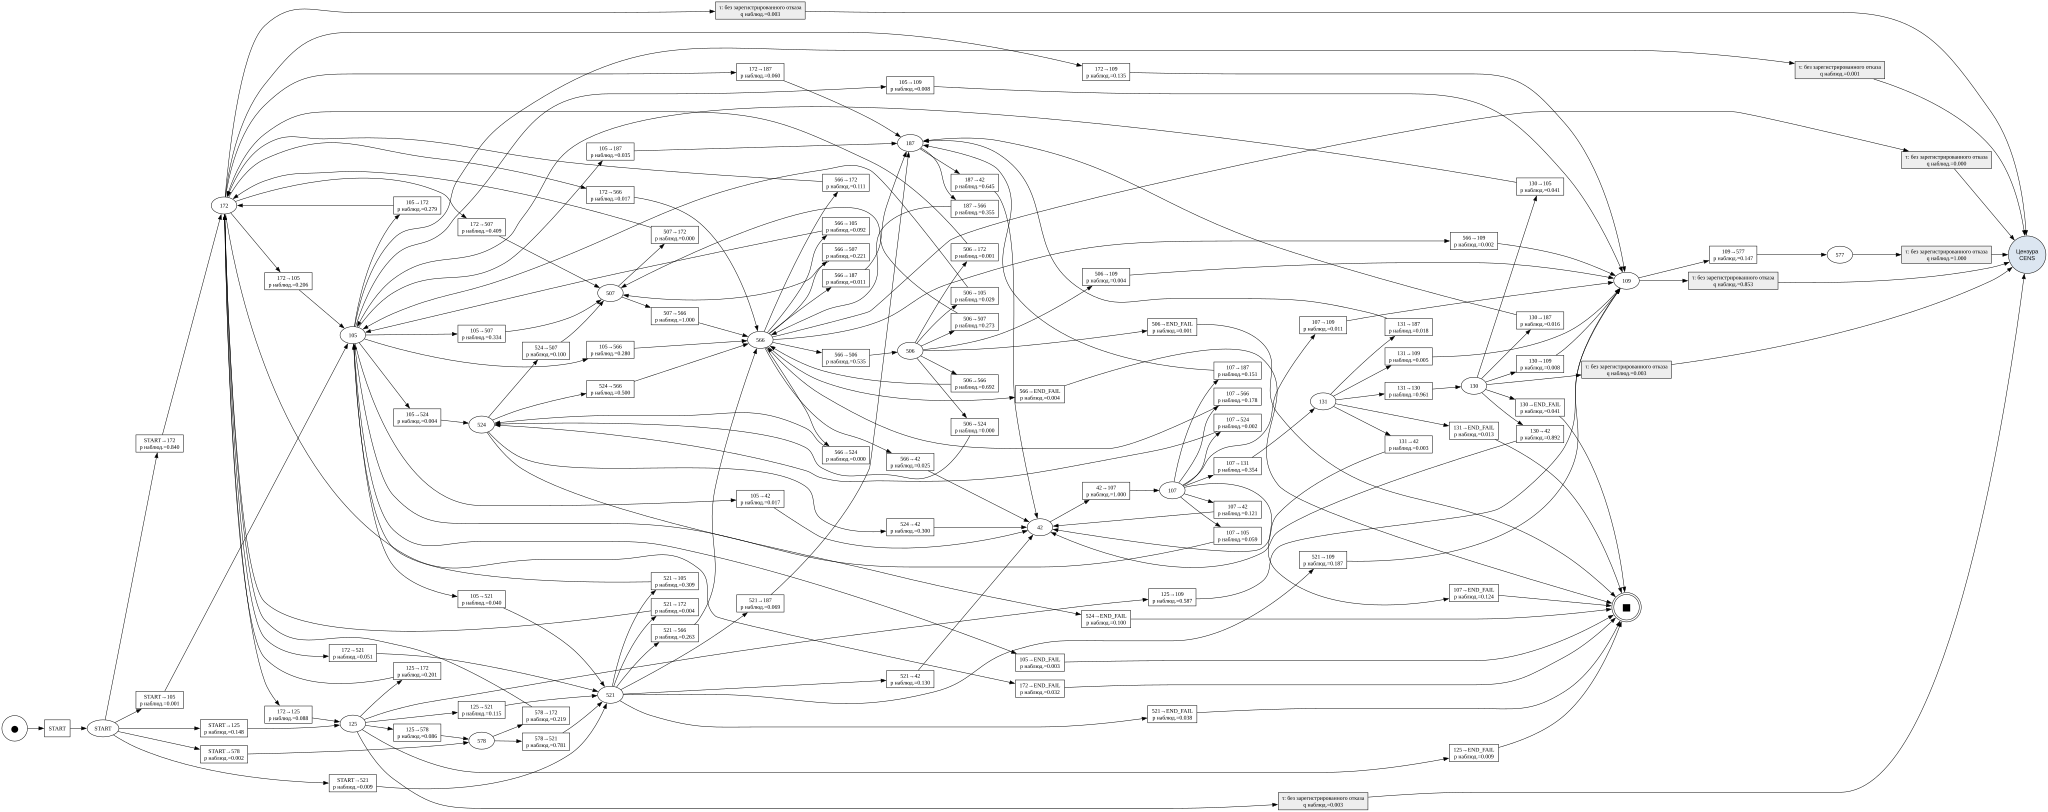

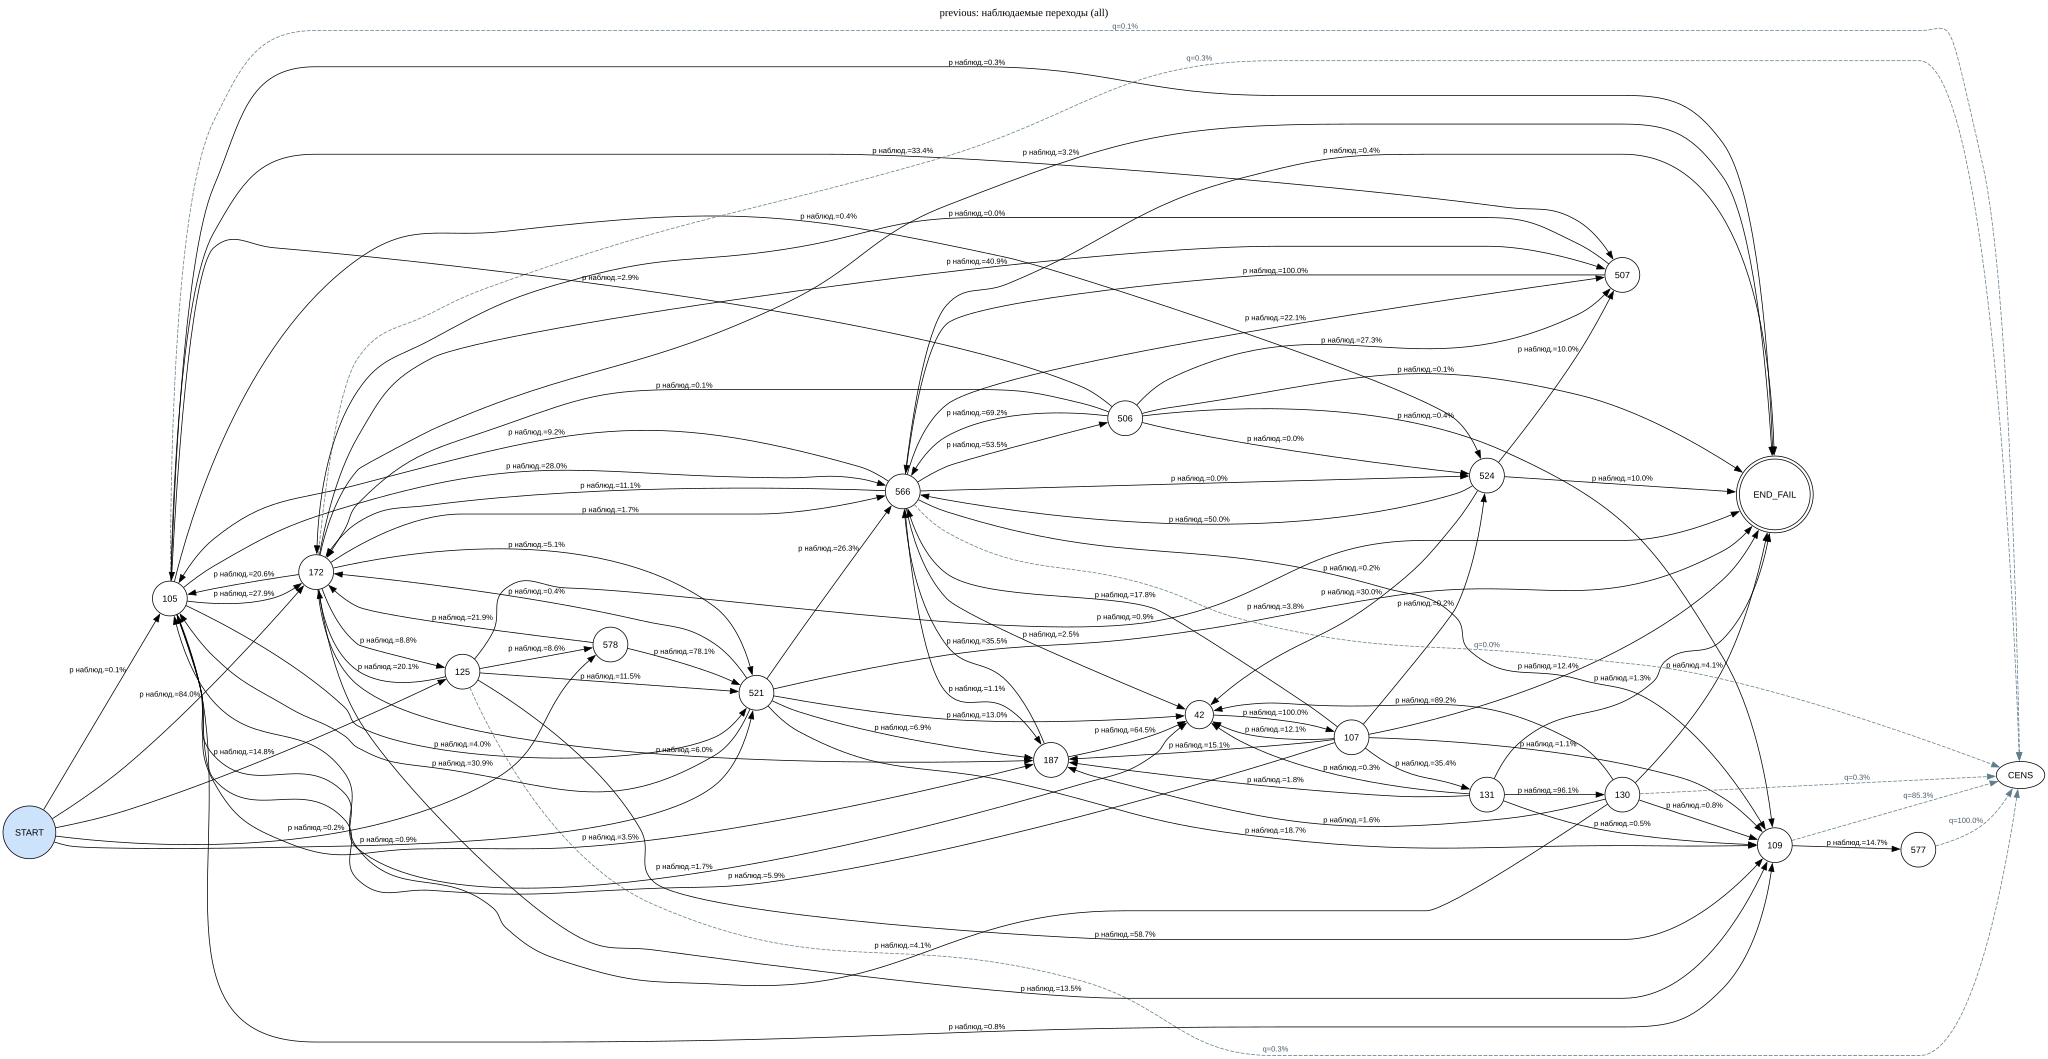

Сохранено в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power\clusters
itplgn | all: машин 37, сессий 1528, цензурировано 422


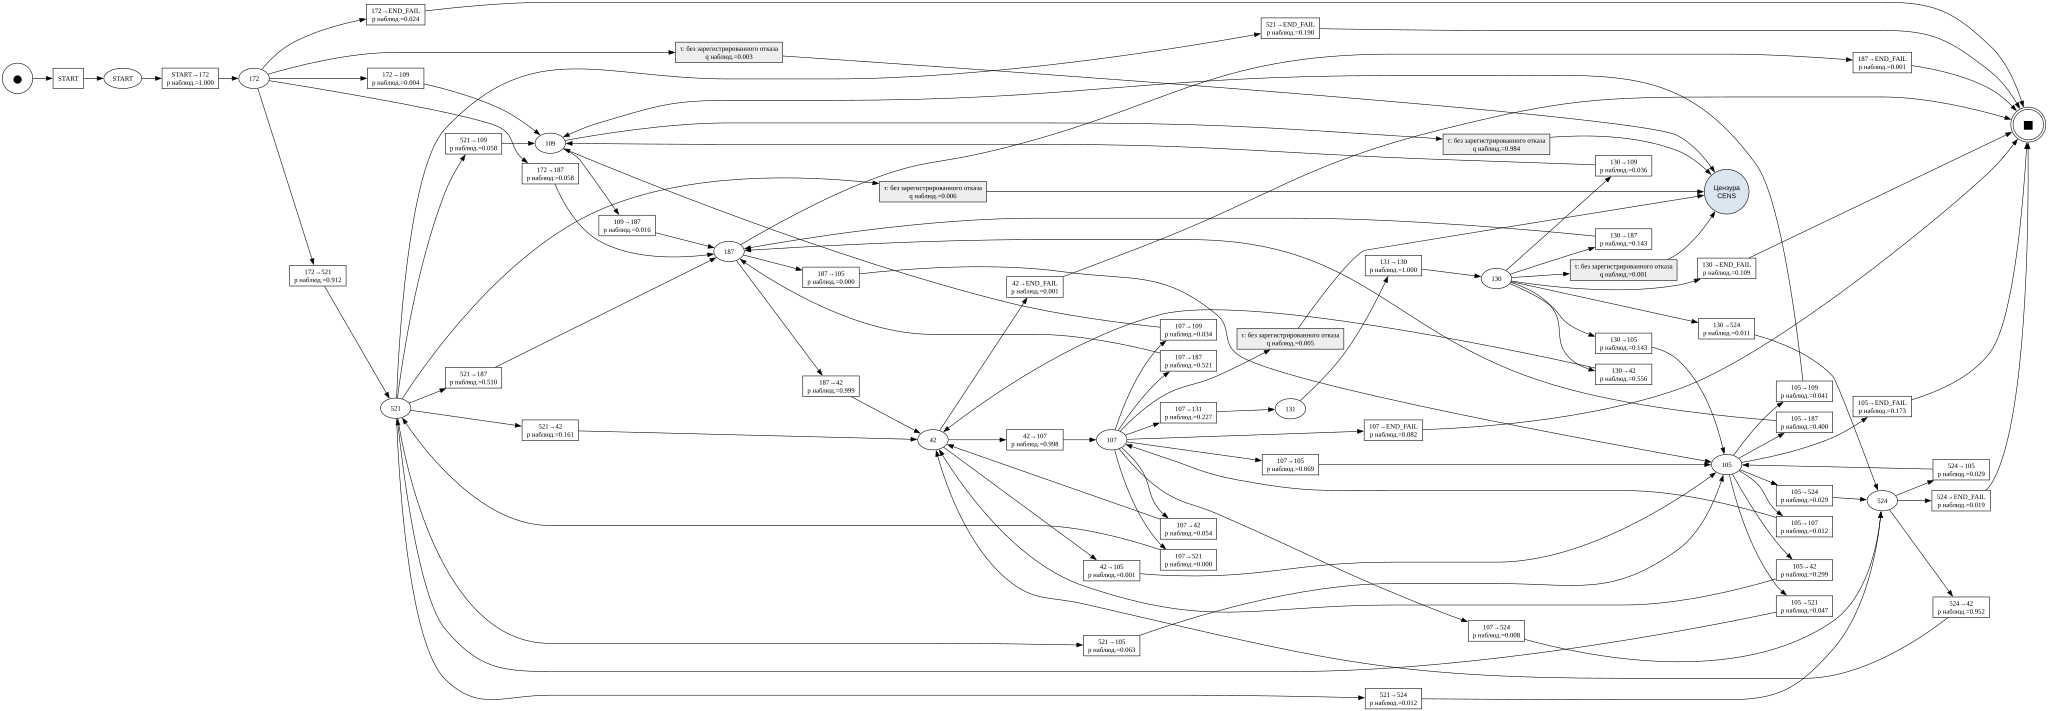

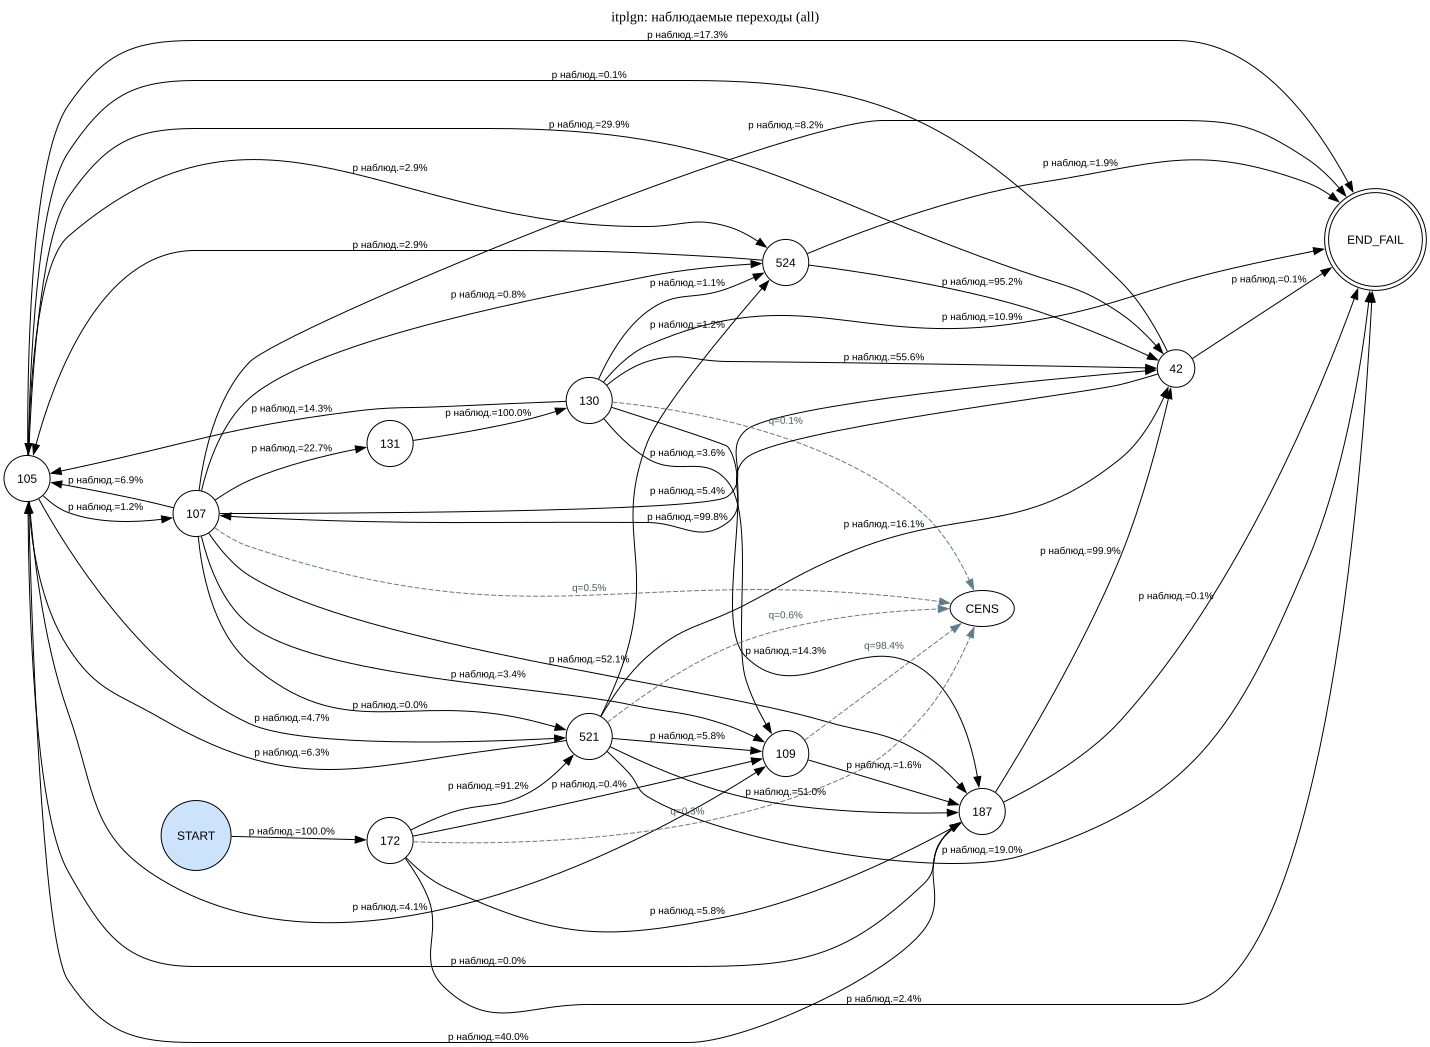

Сохранено в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power\clusters
s-1547-3-410 | all: машин 15, сессий 2003, цензурировано 841


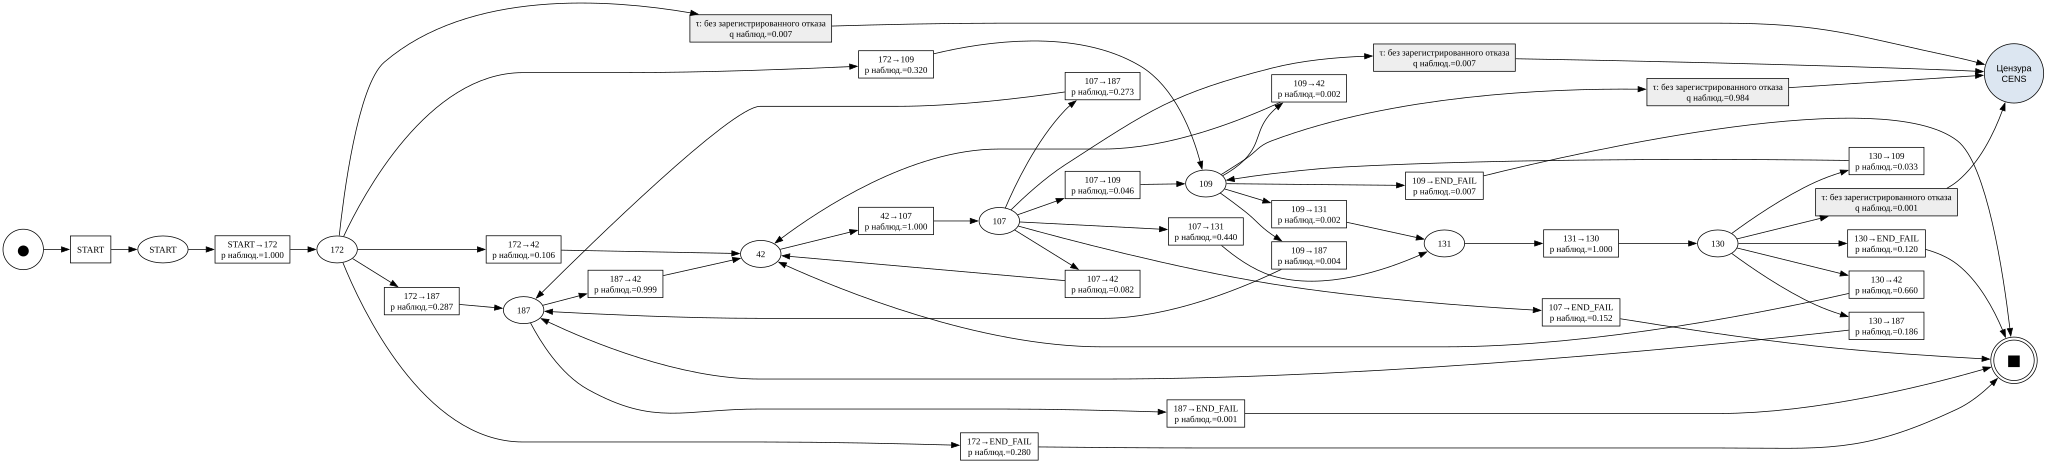

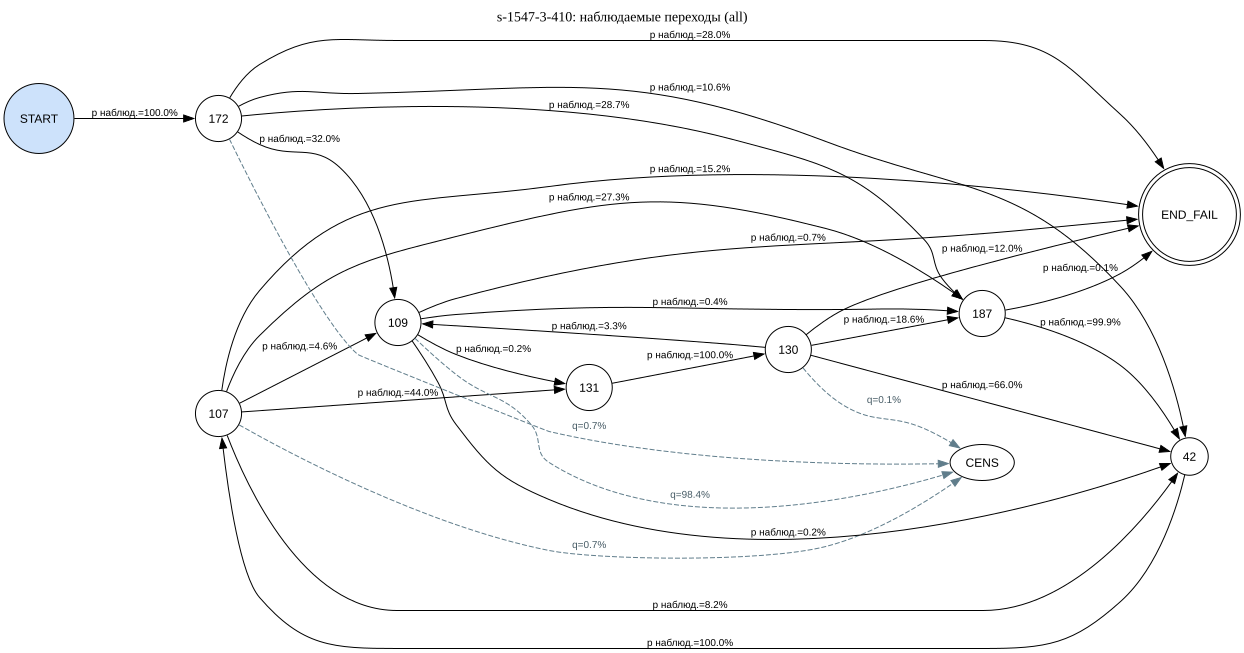

Сохранено в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power\clusters
s-1547-3-413 | all: машин 15, сессий 1533, цензурировано 949


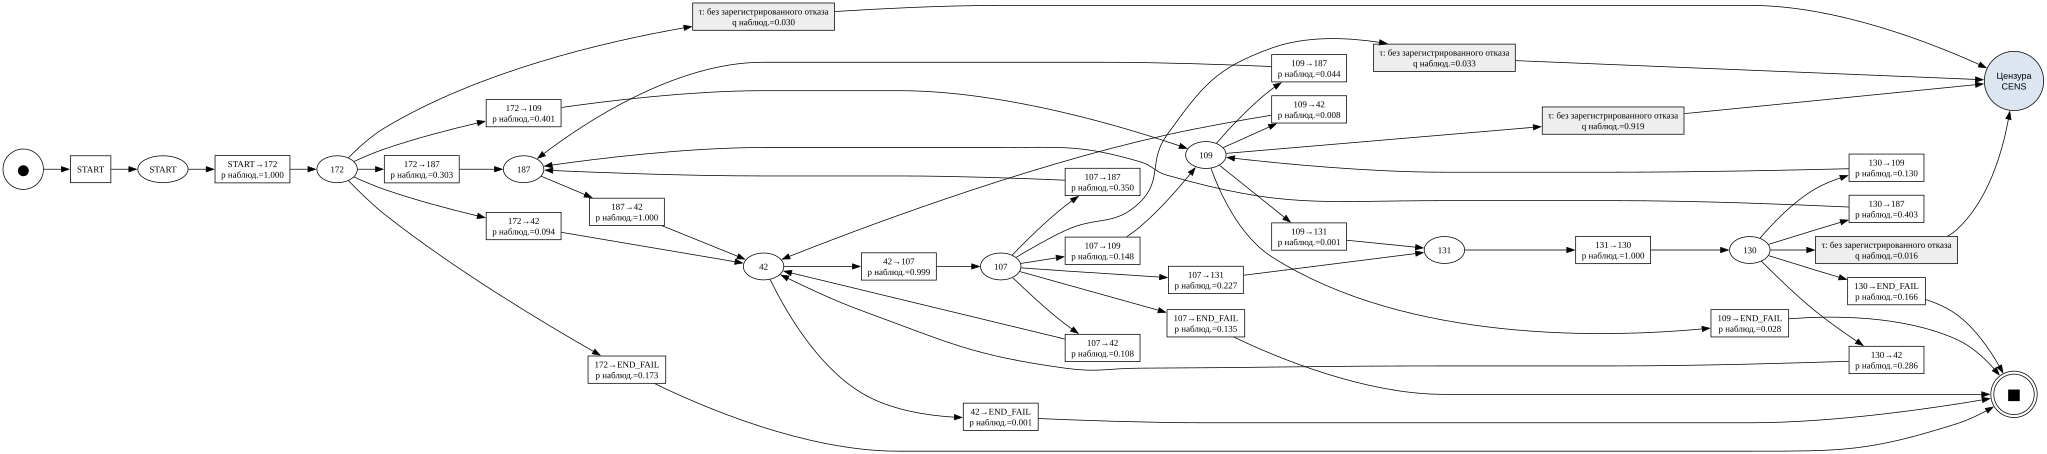

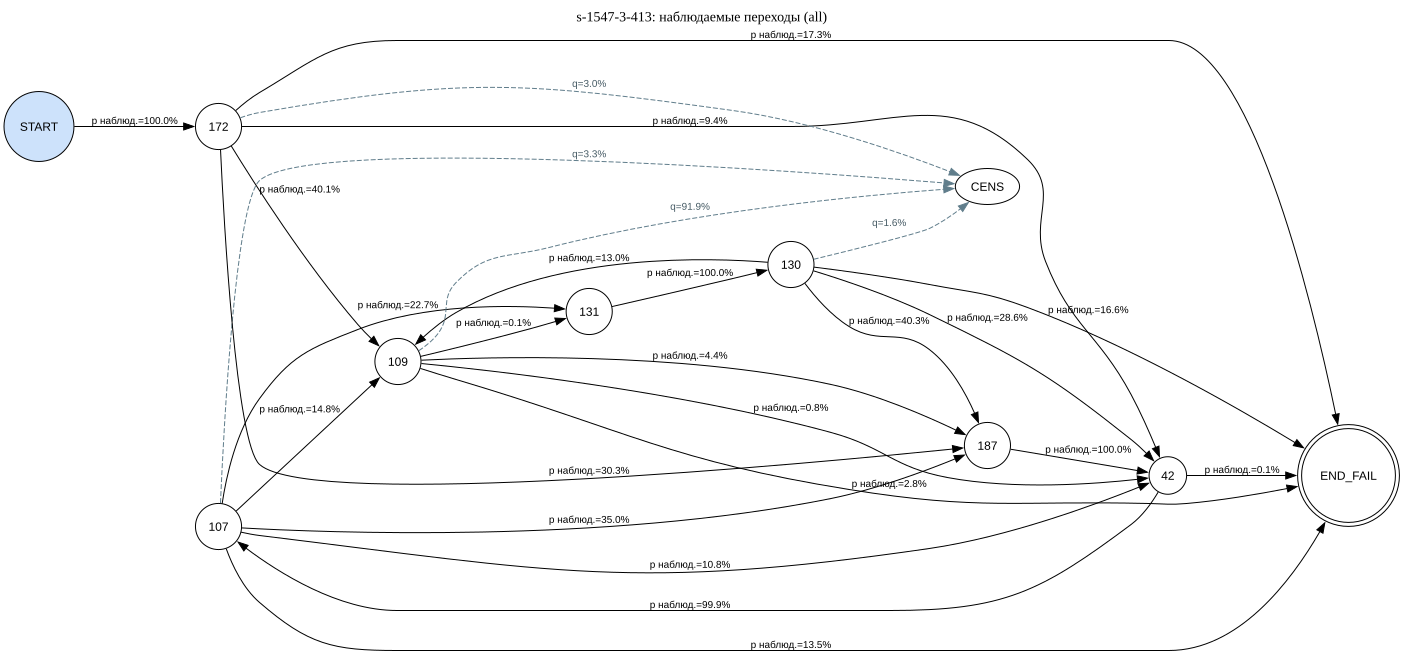

Сохранено в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power\clusters
all_groups | all: машин 81, сессий 6013, цензурировано 2871


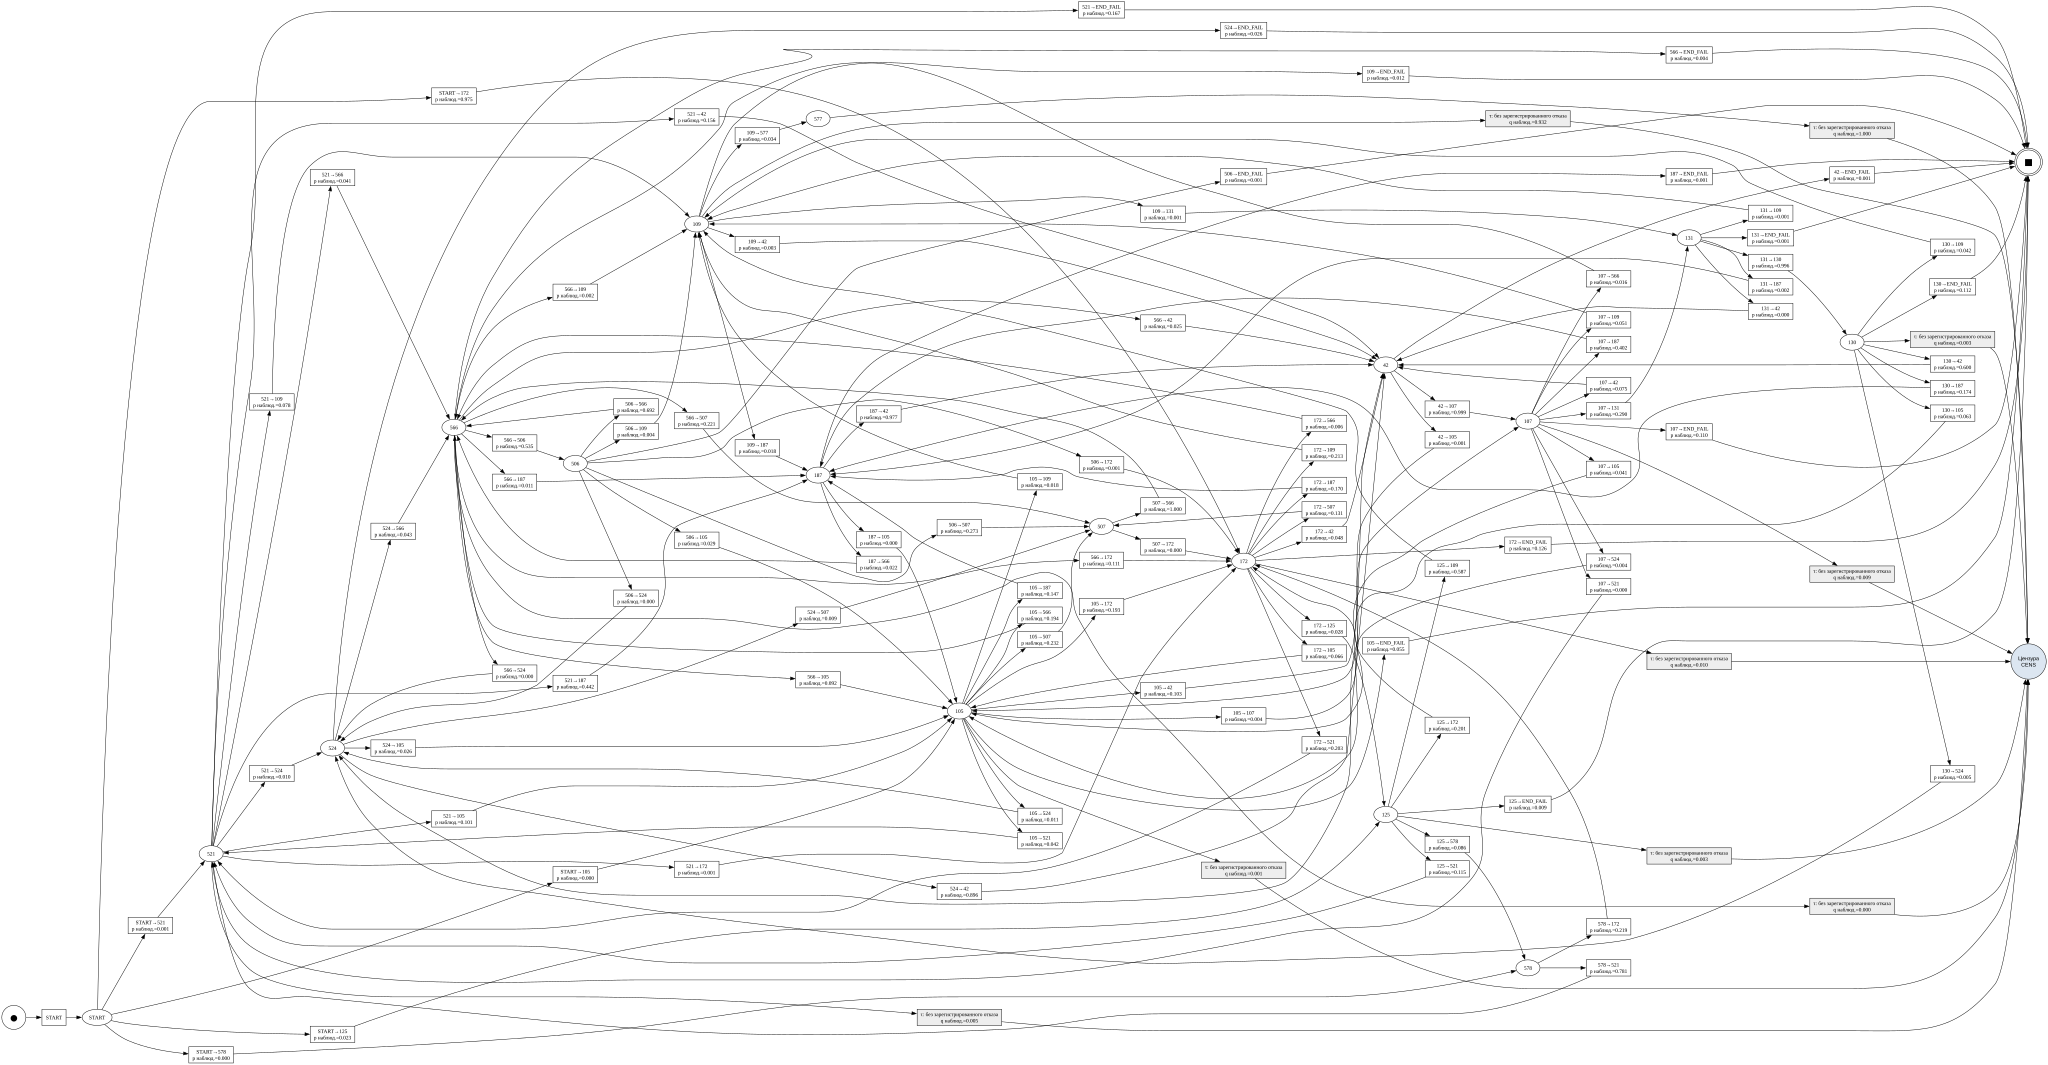

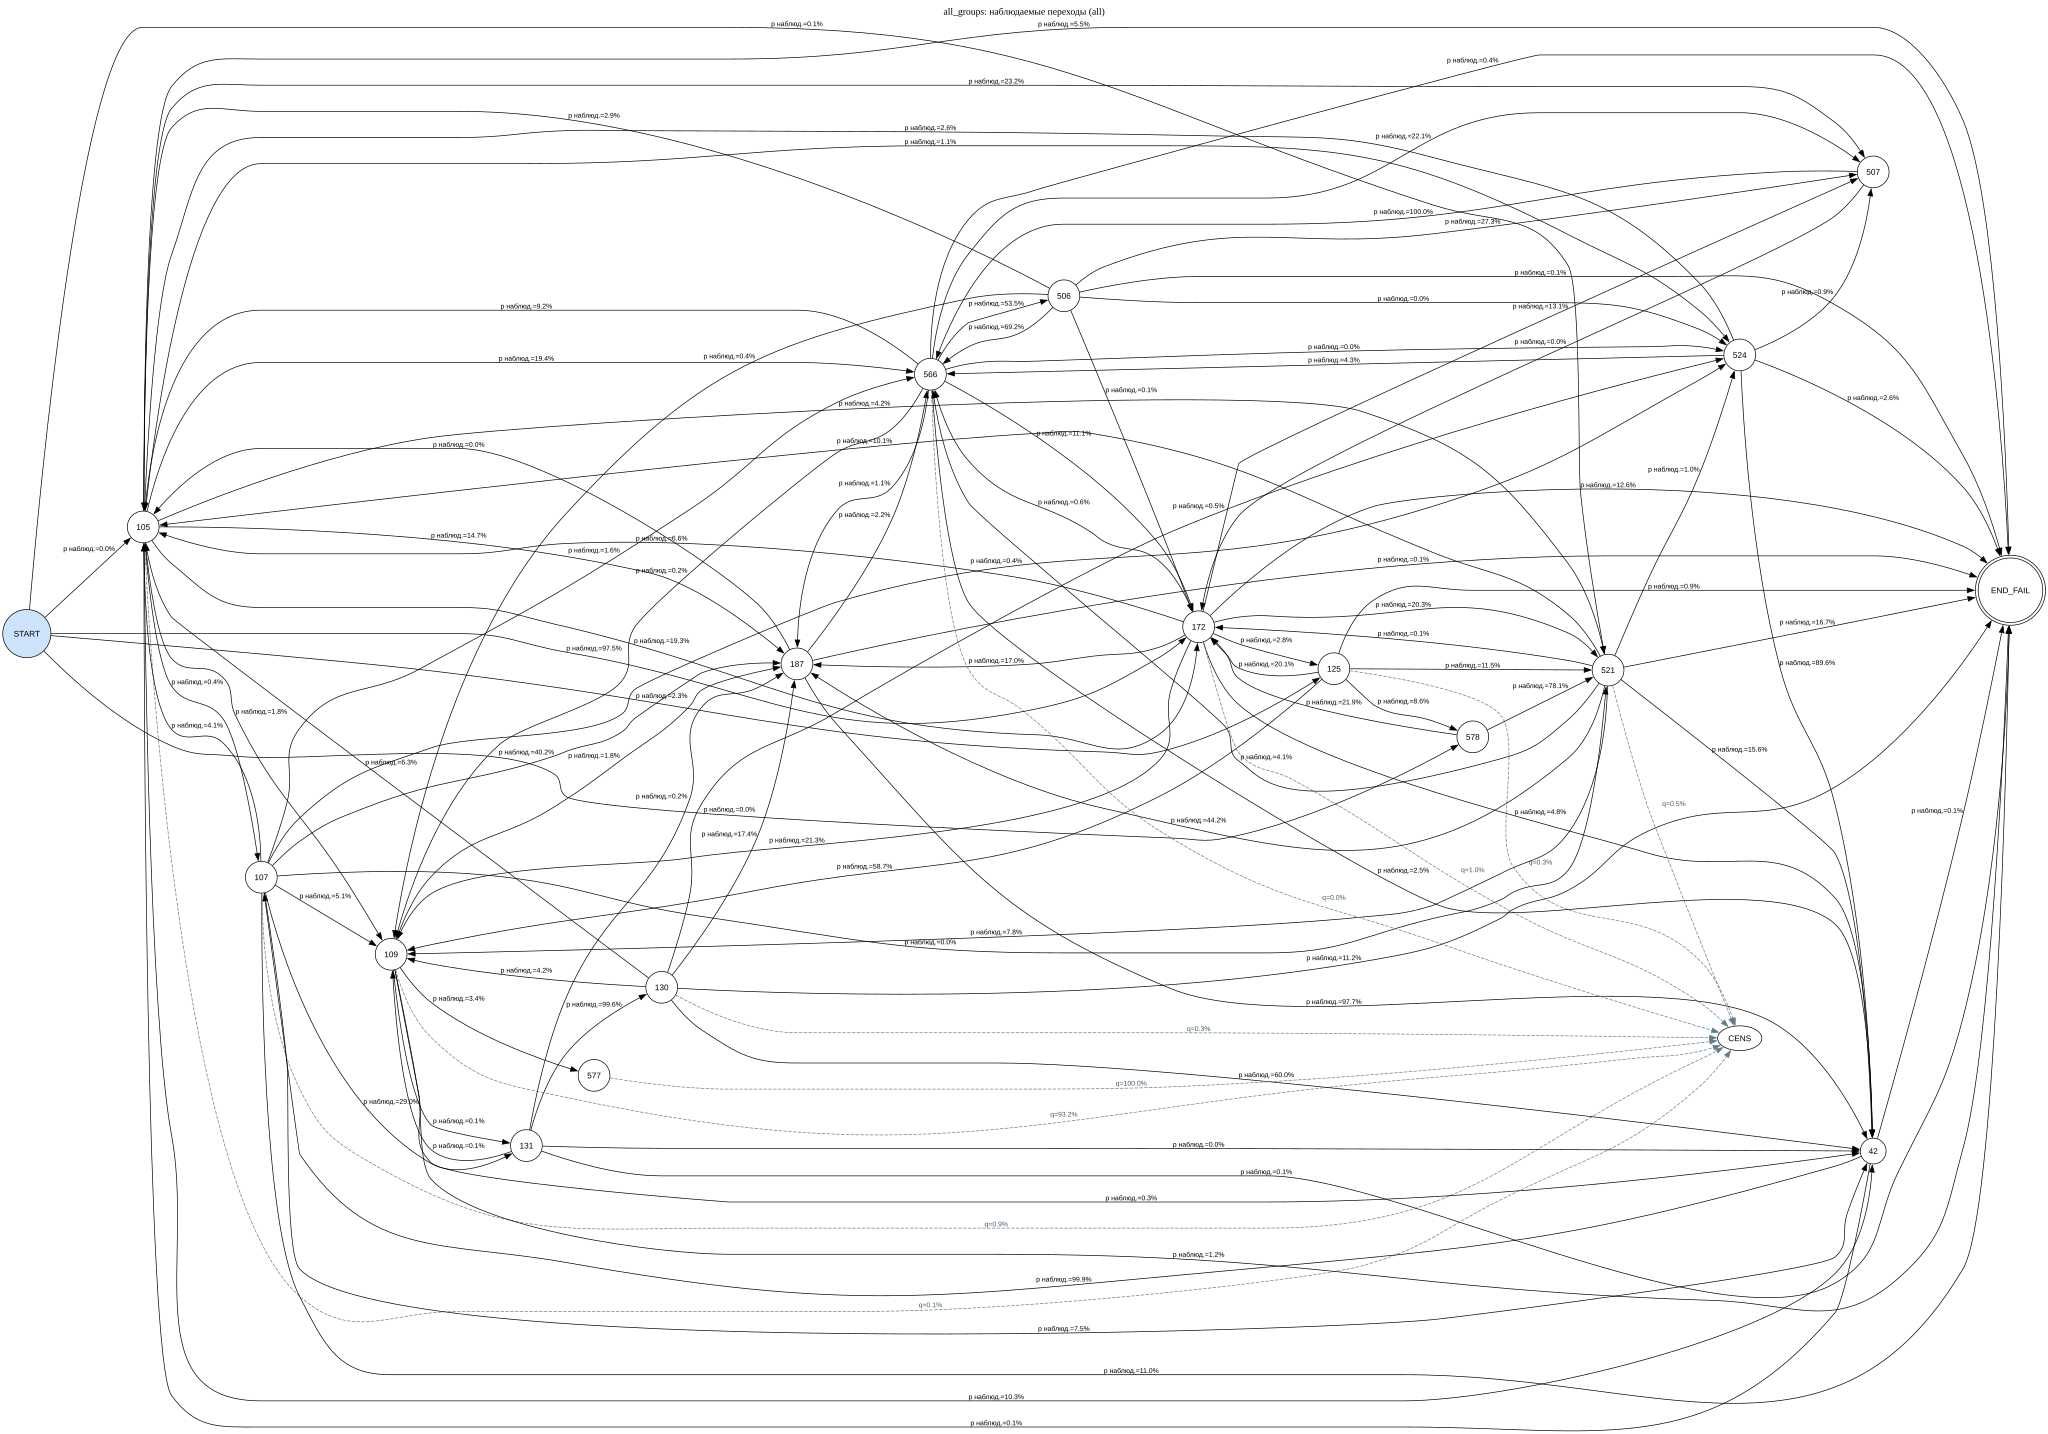

Сохранено в: c:\Users\lena\Desktop\diplom\EquipmentEventLogGeneration\results\petri_nets\kernel_power\clusters


In [18]:
from src.cluster_comparison import component_intervals_for_visualization
from src import censored_petri as cp
import shutil

VISUALIZE_TARGETS = GROUPS + ["all_groups"]     # или ["all_groups"], или GROUPS + ["all_groups"]
VISUALIZE_SCOPE = "all"                    # "all" - все данные, "train" - только обучающие машины
VISUALIZE_STYLE = "both"                  # "petri", "graph", "both"
SHOW_CENSORED_EXAMPLE = False              # пример фишки в CENS
SAVE_VISUALIZATION = True                 # сохранение SVG только при True

if VISUALIZE_SCOPE not in ("all", "train"):
    raise ValueError('VISUALIZE_SCOPE должен быть "all" или "train"')
if VISUALIZE_STYLE not in ("petri", "graph", "both"):
    raise ValueError('VISUALIZE_STYLE: "petri", "graph" или "both"')
if isinstance(VISUALIZE_TARGETS, str):
    VISUALIZE_TARGETS = [VISUALIZE_TARGETS]

chosen_log = log if VISUALIZE_SCOPE == "all" else train
visual_intervals = component_intervals_for_visualization(chosen_log, sessions)
available_machines = set(chosen_log["machine_id"])
if shutil.which("dot") is None:
    print("Graphviz (dot) не найден в PATH. Для отображения SVG нужен установленный Graphviz.")
else:
    for target in VISUALIZE_TARGETS:
        if target == "all_groups":
            part = visual_intervals
        elif target in GROUPS:
            part = visual_intervals.loc[visual_intervals["group"] == target]
        elif target in available_machines:
            part = visual_intervals.loc[visual_intervals["machine_id"] == target]
        else:
            raise ValueError(f"Неизвестная группа/машина: {target}. Список машин: stats['machine_id']")
        if part.empty:
            raise ValueError(f"Нет интервалов для {target} в режиме {VISUALIZE_SCOPE}")

        n_cases = part["case_id"].nunique()
        n_machines = part["machine_id"].nunique()
        n_censored = part.loc[~part["observed"], "case_id"].nunique()
        print(f"{target} | {VISUALIZE_SCOPE}: машин {n_machines}, "
              f"сессий {n_cases}, цензурировано {n_censored}")

        if SAVE_VISUALIZATION:
            folder = root / "results" / "petri_nets" / "kernel_power" / "clusters"
            folder.mkdir(parents=True, exist_ok=True)
            filename = f"{target.replace(':', '_')}_{VISUALIZE_SCOPE}"

        if VISUALIZE_STYLE in ("petri", "both"):
            net, im, fm = cp.state_petri_net(
                part, start="START", terminal="END_FAIL", estimates=None)
            decorations = cp.state_net_decorations(
                net, {"censored": "без зарегистрированного отказа"})
            for tr in net.transitions:
                if tr.name != "start" and not tr.properties.get("censor_reason"):
                    p = tr.properties["observed_probability"]
                    decorations[tr]["label"] = f"{tr.name}\np наблюд.={p:.3f}"

            marking = im
            if SHOW_CENSORED_EXAMPLE:
                cases = part.loc[~part["observed"], "case_id"].drop_duplicates()
                if len(cases):
                    path = part.loc[part["case_id"] == cases.iloc[0]]
                    states = [*path.loc[path["observed"], "src"].tolist(),
                              path["src"].iloc[-1]]
                    marking = cp.replay_censored(net, im, states, reason="censored")
                    print(f"Пример цензурированной сессии: {cases.iloc[0]}")
            picture = cp.draw_state_net(
                net, marking, fm, decorations=decorations,
                reason_labels={"censored": "без зарегистрированного отказа"})
            display(picture)
            if SAVE_VISUALIZATION:
                picture.render(filename=filename + "_petri", directory=str(folder),
                               format="svg", cleanup=True)

        if VISUALIZE_STYLE in ("graph", "both"):
            picture = cp.state_graph(
                part, start="START", terminal="END_FAIL",
                title=f"{target}: наблюдаемые переходы ({VISUALIZE_SCOPE})",
                reason_labels={"censored": "без зарегистрированного отказа"})
            display(picture)
            if SAVE_VISUALIZATION:
                picture.render(filename=filename + "_graph", directory=str(folder),
                               format="svg", cleanup=True)

        if SAVE_VISUALIZATION:
            print("Сохранено в:", folder)